# Diffusion healing: Raju's notebook
**Project:** An inspector that has never seen a defect (MVTec AD, *bottle*)
**My part:** train a DDPM on good bottles only → `heal()` → tune the noise level → score the diffusion heatmaps → figures

**How it works:** add noise to a test image up to step *t* (about 250), then let the DDPM denoise it. The model only knows good bottles, so a defect "heals" away. **|original − healed|** shows where the defect was.

| Day | Run these sections |
|---|---|
| **Day 1** | 0 → 1 → 2 → 3 (5-minute quick check) → 4 (real training run). Leave the tab open overnight. |
| **Day 2** | 0 → 1 → 2, then skip training and run 5 → 6 → 7 (heal, tune, score) |
| **Day 3** | 0 → 1 → 2 → 5, then 8 (figures) and 9 (export for Sohail and Shruti) |

**If Colab disconnects:** run sections 0, 1 and 2 again, then run section 4 again. Training **resumes from the last checkpoint** in Drive.

## 0 · Setup
First do **Runtime → Change runtime type → T4 GPU → Save**, then run the cells below.

In [1]:
!pip -q install diffusers
import torch
print('torch', torch.__version__)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU. Go to Runtime -> Change runtime type -> T4 GPU, then run this cell again.')

torch 2.14.1+cu130
GPU: Tesla T4


In [14]:
# ===================== SETTINGS: edit these if needed =====================
# Everything uses Google Drive:
#  - DATA: the team's data folder in Drive. If DATA_PATH is wrong, the notebook searches
#    your whole Drive (and shortcuts) for the 'bottle' folder by itself.
#  - CHECKPOINTS + RESULTS: saved to RUN_DIR in your Drive every 15 minutes.
DATA_PATH = '/content/drive/MyDrive/data'
DATA_FOLDER_ID = '1FHYWCksormKAm1vYPhUWDz0VoeMr_0tS'   # the team's Drive folder link id
RUN_DIR   = '/content/drive/MyDrive/raju_diffusion'   # checkpoints, results and figures go here

IMG_SIZE   = 64          # train at 64x64 (from the plan)
BATCH_SIZE = 32
LR         = 1e-4
NUM_TRAIN_TIMESTEPS = 1000
BLOCK_CHANNELS = (64, 128, 128, 256)   # UNet width per level

QUICK_MINUTES        = 5       # Day 1 quick check
TARGET_STEPS         = 40000   # real run; on a T4 this takes about 1.5-3 hours
CHECKPOINT_EVERY_MIN = 15      # save to Drive this often

T_START      = 250                                  # first guess for heal()
NOISE_LEVELS = [50, 75, 100, 125, 150, 200, 250, 300, 400, 500]  # levels to try in section 6
BLUR_SIGMA   = 1.0     # smoothing of the 64x64 difference map, in pixels
EVAL_SIZE    = 256     # heatmaps and masks are compared at 256x256
SEED = 0

# ===================== (no need to edit below) =====================
import os, glob, time, copy, json, random, zipfile, tarfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import roc_auc_score
from diffusers import UNet2DModel, DDPMScheduler
import torchvision.transforms.functional as TF

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    assert os.path.isdir('/content/drive/MyDrive'), 'Google Drive is not connected. Run this cell again and click Allow.'
    assert RUN_DIR.startswith('/content/drive/'), 'RUN_DIR must be inside /content/drive so checkpoints are saved to Drive.'

device  = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = device == 'cuda'          # mixed precision on GPU = faster training
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(RUN_DIR, exist_ok=True)
MAIN_DIR  = os.path.join(RUN_DIR, 'main')
QUICK_DIR = os.path.join(RUN_DIR, 'quick_check')
OUT_DIR   = os.path.join(RUN_DIR, 'results')
os.makedirs(OUT_DIR, exist_ok=True)
print('device:', device)
print('Checkpoints and results will be saved in Google Drive:', RUN_DIR.replace('/content/drive/MyDrive', 'My Drive'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda
Checkpoints and results will be saved in Google Drive: My Drive/raju_diffusion


## 1 · Load the bottle images
The data is read from your **Google Drive**. It is copied once to the Colab disk, because reading from there is much faster. If `DATA_PATH` is wrong, the notebook searches your Drive for the `bottle` folder by itself.

searching /content/drive/.shortcut-targets-by-id/1FHYWCksormKAm1vYPhUWDz0VoeMr_0tS ...
copying /content/drive/.shortcut-targets-by-id/1FHYWCksormKAm1vYPhUWDz0VoeMr_0tS/defect-inspector-data/data/bottle ...
bottle data ready (copied from Drive to the fast Colab disk): /content/mvtec/bottle
train (good only): 209 images, tensor (209, 3, 64, 64)
test: {'broken_large': np.int64(20), 'broken_small': np.int64(22), 'contamination': np.int64(21), 'good': np.int64(20)}


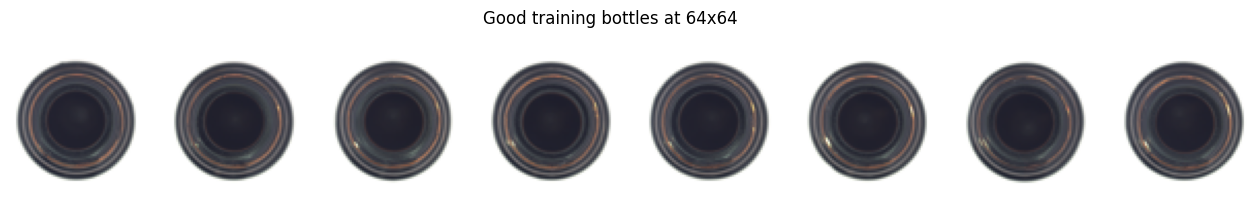

In [3]:
LOCAL_ROOT = '/content/mvtec' if IN_COLAB else os.path.abspath('mvtec_local')

def find_bottle(root):
    if not root or not os.path.isdir(root):
        return None
    hits = glob.glob(os.path.join(root, '**', 'train', 'good'), recursive=True)
    hits = [h for h in hits if 'bottle' in h] or hits
    return os.path.dirname(os.path.dirname(hits[0])) if hits else None

def extract(archive, dest):
    print('extracting', os.path.basename(archive), '...')
    if archive.endswith('.zip'):
        with zipfile.ZipFile(archive) as z: z.extractall(dest)
    else:
        with tarfile.open(archive) as t:
            try: t.extractall(dest, filter='data')
            except TypeError: t.extractall(dest)

def search_drive():
    # Look for .../bottle/train/good anywhere in your Drive, including shared-folder shortcuts
    roots = [os.path.join('/content/drive/.shortcut-targets-by-id', DATA_FOLDER_ID),
             '/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
    for root in roots:
        if not os.path.isdir(root):
            continue
        print('searching', root, '...')
        for dirpath, dirnames, _ in os.walk(root, followlinks=True):
            depth = dirpath[len(root):].count(os.sep)
            if os.path.basename(dirpath) == 'bottle' and os.path.isdir(os.path.join(dirpath, 'train', 'good')):
                return dirpath
            if depth >= 5:
                dirnames[:] = []
            else:
                dirnames[:] = [d for d in dirnames if not d.startswith('.') or d == '.shortcut-targets-by-id']
    return None

def prepare_data(path):
    os.makedirs(LOCAL_ROOT, exist_ok=True)
    bottle = find_bottle(LOCAL_ROOT)
    if bottle: return bottle                      # already copied in this session
    if path and os.path.isfile(path):
        extract(path, LOCAL_ROOT)
    elif path and os.path.isdir(path):
        src = find_bottle(path)
        if src:
            print('copying', src, '...')
            shutil.copytree(src, os.path.join(LOCAL_ROOT, 'bottle'), dirs_exist_ok=True)
        else:
            for a in glob.glob(os.path.join(path, '**', '*.zip'), recursive=True) + \
                     glob.glob(os.path.join(path, '**', '*.tar.xz'), recursive=True):
                extract(a, LOCAL_ROOT)
    bottle = find_bottle(LOCAL_ROOT)
    if bottle is None:                            # zip contained only bottle.tar.xz
        for a in glob.glob(os.path.join(LOCAL_ROOT, '**', '*.tar.xz'), recursive=True):
            extract(a, os.path.dirname(a))
        bottle = find_bottle(LOCAL_ROOT)
    if bottle is None:
        src = search_drive()
        if src:
            print('copying', src, '...')
            shutil.copytree(src, os.path.join(LOCAL_ROOT, 'bottle'), dirs_exist_ok=True)
            bottle = find_bottle(LOCAL_ROOT)
    assert bottle, ('Bottle data not found in your Drive. Open the team folder link in your browser, '
                    'right-click it -> Organize -> Add shortcut -> My Drive, then run this cell again.')
    return bottle

BOTTLE = prepare_data(DATA_PATH)
print('bottle data ready (copied from Drive to the fast Colab disk):', BOTTLE)

def load_rgb(p, size):
    im = Image.open(p).convert('RGB').resize((size, size), Image.BICUBIC)
    return np.asarray(im, dtype=np.float32) / 255.0

def to_model(arr):            # (N,H,W,3) in [0,1] -> (N,3,H,W) in [-1,1]
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2) * 2 - 1

def to_img(x):                # (3,H,W) in [-1,1] -> (H,W,3) in [0,1] for plotting
    return ((x.detach().cpu().float().permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()

train_paths = sorted(glob.glob(os.path.join(BOTTLE, 'train', 'good', '*.png')))
train_x = to_model([load_rgb(p, IMG_SIZE) for p in train_paths])

# test set: good + every defect type, with ground-truth masks
test_paths, test_types, test_masks = [], [], []
for dtype in sorted(os.listdir(os.path.join(BOTTLE, 'test'))):
    for p in sorted(glob.glob(os.path.join(BOTTLE, 'test', dtype, '*.png'))):
        test_paths.append(p); test_types.append(dtype)
        if dtype == 'good':
            test_masks.append(np.zeros((EVAL_SIZE, EVAL_SIZE), dtype=bool))
        else:
            stem = os.path.splitext(os.path.basename(p))[0]
            mp = os.path.join(BOTTLE, 'ground_truth', dtype, stem + '_mask.png')
            m = Image.open(mp).convert('L').resize((EVAL_SIZE, EVAL_SIZE), Image.NEAREST)
            test_masks.append(np.asarray(m) > 127)
test_x      = to_model([load_rgb(p, IMG_SIZE) for p in test_paths])
test_types  = np.array(test_types)
test_labels = (test_types != 'good').astype(int)
test_masks  = np.stack(test_masks)

print(f'train (good only): {len(train_x)} images, tensor {tuple(train_x.shape)}')
print('test:', dict(pd.Series(test_types).value_counts().sort_index()))

fig, ax = plt.subplots(1, 8, figsize=(16, 2.3))
for i, a in enumerate(ax):
    a.imshow(to_img(train_x[i * len(train_x) // 8])); a.axis('off')
plt.suptitle('Good training bottles at 64x64'); plt.show()

## 2 · The DDPM: `UNet2DModel` + `DDPMScheduler`
The UNet starts untrained. It learns to predict the noise that was added to a good bottle at a random step *t* (out of 1,000).

In [4]:
def make_model():
    return UNet2DModel(
        sample_size=IMG_SIZE, in_channels=3, out_channels=3, layers_per_block=2,
        block_out_channels=BLOCK_CHANNELS,
        down_block_types=('DownBlock2D', 'DownBlock2D', 'AttnDownBlock2D', 'DownBlock2D'),
        up_block_types=('UpBlock2D', 'AttnUpBlock2D', 'UpBlock2D', 'UpBlock2D'),
    )

scheduler = DDPMScheduler(num_train_timesteps=NUM_TRAIN_TIMESTEPS, beta_schedule='linear')
print(f'UNet parameters: {sum(p.numel() for p in make_model().parameters())/1e6:.1f} M')

def augment(x):
    # random horizontal/vertical flips + random 90-degree rotations (bottles are seen from the top)
    B = x.shape[0]
    fh = (torch.rand(B, device=x.device) < 0.5)[:, None, None, None]
    fv = (torch.rand(B, device=x.device) < 0.5)[:, None, None, None]
    x = torch.where(fh, x.flip(3), x)
    x = torch.where(fv, x.flip(2), x)
    ks = torch.randint(0, 4, (B,)).tolist()
    return torch.stack([torch.rot90(xi, k, (1, 2)) for xi, k in zip(x, ks)])

def save_ckpt(run_dir, state):
    path = os.path.join(run_dir, 'ckpt_latest.pt')
    tmp = path + '.tmp'
    torch.save(state, tmp)
    if os.path.exists(path):                     # keep the previous one as a backup
        os.replace(path, os.path.join(run_dir, 'ckpt_prev.pt'))
    os.replace(tmp, path)

def load_ckpt(run_dir):
    for name in ('ckpt_latest.pt', 'ckpt_prev.pt'):
        p = os.path.join(run_dir, name)
        if os.path.exists(p):
            try:
                return torch.load(p, map_location=device, weights_only=False)
            except Exception as e:
                print(f'could not read {name} ({e}), trying the backup')
    return None

def train(run_dir, max_steps, minutes=None, resume=True):
    # Train the DDPM. Saves to Drive every CHECKPOINT_EVERY_MIN minutes and at the end.
    # resume=True continues from the latest checkpoint in run_dir.
    # Stopping the cell (the stop button) also saves a checkpoint.
    global model, ema
    os.makedirs(run_dir, exist_ok=True)
    model = make_model().to(device)
    ema = copy.deepcopy(model).eval().requires_grad_(False)   # smoothed weights, used for healing
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    step, losses = 0, []
    ck = load_ckpt(run_dir) if resume else None
    if ck:
        model.load_state_dict(ck['model']); ema.load_state_dict(ck['ema'])
        opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        step, losses = ck['step'], ck['losses']
        print(f'Resumed from step {step}')
    if step >= max_steps:
        print(f'Already trained to step {step} (target {max_steps}). Nothing to do.')
        return losses
    state = lambda: {'model': model.state_dict(), 'ema': ema.state_dict(), 'opt': opt.state_dict(),
                     'scaler': scaler.state_dict(), 'step': step, 'losses': losses,
                     'config': {'IMG_SIZE': IMG_SIZE, 'BLOCK_CHANNELS': BLOCK_CHANNELS}}
    data = train_x.to(device)
    model.train()
    t0 = last_save = last_log = time.time()
    run_loss, n_loss, start_step = 0.0, 0, step
    try:
        while step < max_steps:
            if minutes is not None and time.time() - t0 > minutes * 60:
                break
            x0 = augment(data[torch.randint(0, len(data), (BATCH_SIZE,), device=device)])
            noise = torch.randn_like(x0)
            t = torch.randint(0, NUM_TRAIN_TIMESTEPS, (BATCH_SIZE,), device=device)
            xt = scheduler.add_noise(x0, noise, t)                         # forward process
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                pred = model(xt, t).sample                                 # predict the noise
            loss = F.mse_loss(pred.float(), noise)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            decay = min(0.999, (1 + step) / (10 + step))
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1 - decay)
            step += 1
            run_loss += loss.detach(); n_loss += 1
            if step % 100 == 0:
                losses.append((step, (run_loss / n_loss).item())); run_loss, n_loss = 0.0, 0
            if time.time() - last_log > 60 or step == max_steps:
                el = time.time() - t0
                its = (step - start_step) / el
                eta = (max_steps - step) / its / 60 if minutes is None else max(0, minutes - el / 60)
                print(f'step {step:6d} | loss {(run_loss / n_loss).item() if n_loss else losses[-1][1]:.4f} | '
                      f'{its:.1f} it/s | {el/60:.1f} min | ~{eta:.0f} min left', flush=True)
                last_log = time.time()
            if time.time() - last_save > CHECKPOINT_EVERY_MIN * 60:
                save_ckpt(run_dir, state()); last_save = time.time()
                print(f'  checkpoint saved at step {step}', flush=True)
    except KeyboardInterrupt:
        print('Stopped by you. Saving a checkpoint...')
    if n_loss:
        losses.append((step, float(run_loss / n_loss)))
    save_ckpt(run_dir, state())
    print(f'Saved checkpoint at step {step} -> {run_dir}')
    model.eval()
    return losses

@torch.no_grad()
def generate(net, n=4, seed=SEED):
    # Generate new bottles from pure noise (full reverse process, 1,000 steps)
    sched = DDPMScheduler.from_config(scheduler.config)
    sched.set_timesteps(NUM_TRAIN_TIMESTEPS)
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 3, IMG_SIZE, IMG_SIZE, generator=g, device=device)
    for t in sched.timesteps:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            eps = net(x, t).sample
        x = sched.step(eps.float(), t, x, generator=g).prev_sample
    return x.clamp(-1, 1)

def show_row(imgs, title, labels=None):
    fig, ax = plt.subplots(1, len(imgs), figsize=(2.4 * len(imgs), 2.6))
    for i, a in enumerate(np.atleast_1d(ax)):
        a.imshow(to_img(imgs[i])); a.axis('off')
        if labels: a.set_title(labels[i], fontsize=9)
    plt.suptitle(title); plt.show()

UNet parameters: 17.2 M


## 3 · Day 1 quick check: train 5 minutes, generate 4 images
**Done when:** you see blurry bottle shapes and nothing crashes. This run saves to a separate `quick_check` folder, so it does not affect the real run.

step    271 | loss 0.0322 | 4.5 it/s | 1.0 min | ~4 min left
step    539 | loss 0.0171 | 4.5 it/s | 2.0 min | ~3 min left
step    809 | loss 0.0132 | 4.5 it/s | 3.0 min | ~2 min left
step   1078 | loss 0.0107 | 4.5 it/s | 4.0 min | ~1 min left
Saved checkpoint at step 1342 -> /content/drive/MyDrive/raju_diffusion/quick_check


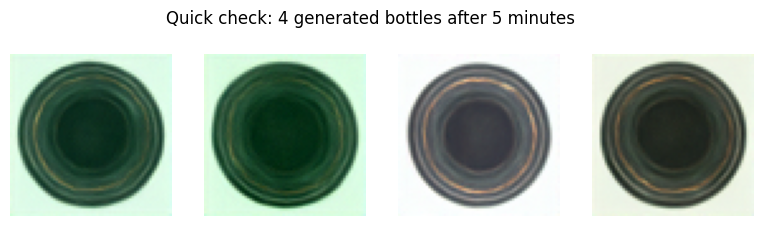

In [5]:
train(QUICK_DIR, max_steps=10**9, minutes=QUICK_MINUTES, resume=False)
show_row(generate(model, n=4), f'Quick check: 4 generated bottles after {QUICK_MINUTES} minutes')

## 4 · The real training run (start on Day 1, leave it overnight)
- This saves `ckpt_latest.pt` to `raju_diffusion/main` in Drive every 15 minutes.
- **If Colab disconnects:** reconnect, run sections **0, 1 and 2**, then run this cell again. It resumes from the checkpoint.
- **To stop early:** click the stop button. A checkpoint is saved before it stops.
- The loss should drop quickly and then level off at roughly 0.02–0.05.

In [6]:
losses = train(MAIN_DIR, max_steps=TARGET_STEPS, resume=True)

step    267 | loss 0.0291 | 4.4 it/s | 1.0 min | ~149 min left
step    535 | loss 0.0156 | 4.5 it/s | 2.0 min | ~148 min left
step    803 | loss 0.0155 | 4.5 it/s | 3.0 min | ~147 min left
step   1072 | loss 0.0128 | 4.5 it/s | 4.0 min | ~146 min left
step   1340 | loss 0.0113 | 4.5 it/s | 5.0 min | ~145 min left
step   1609 | loss 0.0074 | 4.5 it/s | 6.0 min | ~144 min left
step   1878 | loss 0.0071 | 4.5 it/s | 7.0 min | ~142 min left
step   2146 | loss 0.0070 | 4.5 it/s | 8.0 min | ~141 min left
step   2415 | loss 0.0063 | 4.5 it/s | 9.0 min | ~140 min left
step   2684 | loss 0.0063 | 4.5 it/s | 10.0 min | ~139 min left
step   2952 | loss 0.0074 | 4.5 it/s | 11.0 min | ~138 min left
step   3221 | loss 0.0061 | 4.5 it/s | 12.0 min | ~137 min left
step   3489 | loss 0.0066 | 4.5 it/s | 13.0 min | ~136 min left
step   3758 | loss 0.0070 | 4.5 it/s | 14.0 min | ~135 min left
  checkpoint saved at step 4019
step   4023 | loss 0.0054 | 4.5 it/s | 15.0 min | ~134 min left
step   4291 | los

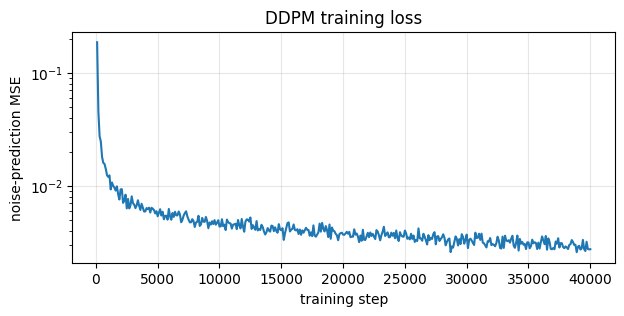

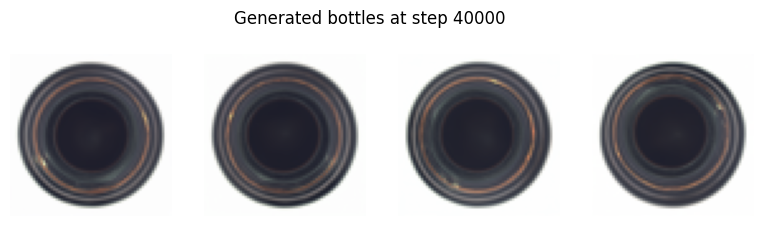

In [7]:
# loss curve + 4 samples from the smoothed (EMA) model
ck = load_ckpt(MAIN_DIR)
s, l = zip(*ck['losses']) if ck['losses'] else ([0], [float('nan')])
plt.figure(figsize=(7, 3)); plt.plot(s, l); plt.yscale('log')
plt.xlabel('training step'); plt.ylabel('noise-prediction MSE'); plt.title('DDPM training loss')
plt.grid(alpha=.3); plt.savefig(os.path.join(OUT_DIR, 'loss_curve.png'), dpi=150, bbox_inches='tight'); plt.show()
ema = make_model().to(device); ema.load_state_dict(ck['ema']); ema.eval()
show_row(generate(ema, n=4), f'Generated bottles at step {ck["step"]}')

## 5 · `heal()`: add noise up to step *t*, then denoise back
**Day 2 / Day 3:** after running sections 0–2, start here. You do not need to train again. This loads the trained model from Drive.

Loaded EMA model trained for 40000 steps


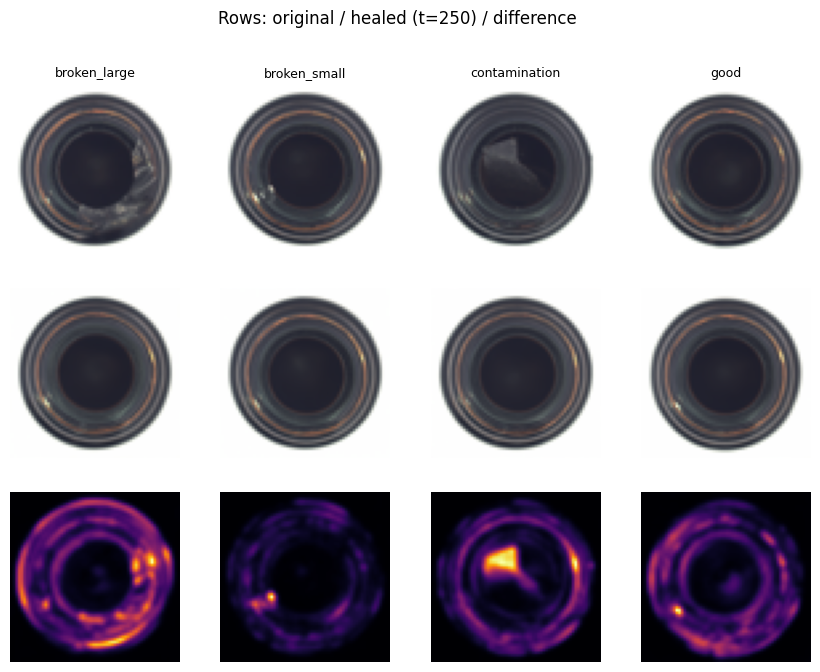

In [8]:
ck = load_ckpt(MAIN_DIR)
assert ck is not None, 'No checkpoint in RUN_DIR/main yet. Run section 4 first.'
ema = make_model().to(device); ema.load_state_dict(ck['ema']); ema.eval()
print(f'Loaded EMA model trained for {ck["step"]} steps')

@torch.no_grad()
def heal(net, x0, t_start=T_START, seed=SEED, batch=64):
    # x0: (N,3,H,W) in [-1,1].  Forward: jump straight to x_t with t = t_start-1.
    # Reverse: run the DDPM back to step 0. Defects are 'healed' into good bottle.
    sched = DDPMScheduler.from_config(scheduler.config)
    sched.set_timesteps(NUM_TRAIN_TIMESTEPS)
    steps = sched.timesteps[sched.timesteps < t_start]          # t_start-1, ..., 1, 0
    out = []
    for i in range(0, len(x0), batch):
        xb = x0[i:i + batch].to(device)
        g = torch.Generator(device=device).manual_seed(seed + i)
        noise = torch.randn(xb.shape, generator=g, device=device)
        x = sched.add_noise(xb, noise, torch.full((len(xb),), t_start - 1, device=device, dtype=torch.long))
        for t in steps:
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                eps = net(x, t).sample
            x = sched.step(eps.float(), t, x, generator=g).prev_sample
        out.append(x.clamp(-1, 1).cpu())
    return torch.cat(out)

def anomaly_map(x, healed, sigma=BLUR_SIGMA):
    # |original - healed|, averaged over RGB, lightly blurred. Returns (N,H,W).
    d = (x - healed).abs().mean(1, keepdim=True)
    if sigma > 0:
        k = 2 * int(np.ceil(3 * sigma)) + 1
        d = TF.gaussian_blur(d, kernel_size=k, sigma=sigma)
    return d[:, 0]

# try it on one example per test type
idx = [int(np.where(test_types == t)[0][0]) for t in np.unique(test_types)]
h = heal(ema, test_x[idx], t_start=T_START)
m = anomaly_map(test_x[idx], h)
fig, ax = plt.subplots(3, len(idx), figsize=(2.6 * len(idx), 7.5))
for j, i in enumerate(idx):
    ax[0, j].imshow(to_img(test_x[i])); ax[0, j].set_title(test_types[i], fontsize=9)
    ax[1, j].imshow(to_img(h[j])); ax[2, j].imshow(m[j], cmap='inferno')
for a in ax.ravel(): a.axis('off')
ax[0, 0].set_ylabel('original'); plt.suptitle(f'Rows: original / healed (t={T_START}) / difference'); plt.show()

## 6 · Score the heatmaps and tune the noise level
- **Image AUROC**: is the bottle defective? The image score is the maximum value of its heatmap.
- **Pixel AUROC**: is the heatmap in the right place? It is checked against the ground-truth masks.

If *t* is too small, the defect does not heal. If *t* is too large, the whole bottle gets redrawn and good areas light up too.

t=  50  image AUROC 0.990  pixel AUROC 0.958  (14s)
t=  75  image AUROC 0.981  pixel AUROC 0.954  (22s)
t= 100  image AUROC 0.976  pixel AUROC 0.952  (25s)
t= 125  image AUROC 0.973  pixel AUROC 0.949  (31s)
t= 150  image AUROC 0.960  pixel AUROC 0.945  (36s)
t= 200  image AUROC 0.939  pixel AUROC 0.935  (48s)
t= 250  image AUROC 0.924  pixel AUROC 0.927  (58s)
t= 300  image AUROC 0.902  pixel AUROC 0.916  (70s)
t= 400  image AUROC 0.829  pixel AUROC 0.892  (93s)
t= 500  image AUROC 0.810  pixel AUROC 0.846  (115s)

Best noise level (highest image + pixel AUROC): 50


,t_start,image_auroc,pixel_auroc
0,50,0.9897,0.9577
1,75,0.9810,0.9543
2,100,0.9762,0.9519
3,125,0.9730,0.9489
4,150,0.9595,0.9447
5,200,0.9389,0.9354
6,250,0.9238,0.9271
7,300,0.9016,0.9164
8,400,0.8286,0.8915
9,500,0.8095,0.8464


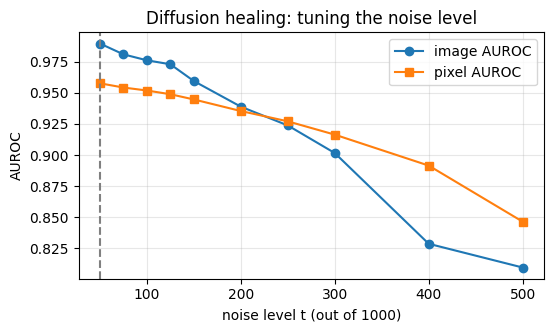

In [15]:
def score(maps):
    # maps: (N,h,w) tensor -> upsample to EVAL_SIZE and compute image and pixel AUROC
    m = F.interpolate(maps[:, None].float(), size=EVAL_SIZE, mode='bilinear', align_corners=False)[:, 0].numpy()
    img_scores = m.reshape(len(m), -1).max(1)
    img_auroc = roc_auc_score(test_labels, img_scores)
    pix_auroc = roc_auc_score(test_masks.ravel().astype(np.uint8), m.ravel())
    return img_auroc, pix_auroc, img_scores, m

rows, healed_by_t = [], {}
for t in NOISE_LEVELS:
    t0 = time.time()
    healed_by_t[t] = heal(ema, test_x, t_start=t)
    ia, pa, _, _ = score(anomaly_map(test_x, healed_by_t[t]))
    rows.append({'t_start': t, 'image_auroc': round(ia, 4), 'pixel_auroc': round(pa, 4)})
    print(f't={t:4d}  image AUROC {ia:.3f}  pixel AUROC {pa:.3f}  ({time.time()-t0:.0f}s)', flush=True)

sweep = pd.DataFrame(rows)
sweep.to_csv(os.path.join(OUT_DIR, 'noise_level_sweep.csv'), index=False)
BEST_T = int(sweep.loc[(sweep.image_auroc + sweep.pixel_auroc).idxmax(), 't_start'])
print('\nBest noise level (highest image + pixel AUROC):', BEST_T)
display(sweep)

plt.figure(figsize=(6, 3.2))
plt.plot(sweep.t_start, sweep.image_auroc, 'o-', label='image AUROC')
plt.plot(sweep.t_start, sweep.pixel_auroc, 's-', label='pixel AUROC')
plt.axvline(BEST_T, ls='--', c='gray'); plt.xlabel('noise level t (out of 1000)'); plt.ylabel('AUROC')
plt.title('Diffusion healing: tuning the noise level'); plt.legend(); plt.grid(alpha=.3)
plt.savefig(os.path.join(OUT_DIR, 'noise_level_sweep.png'), dpi=150, bbox_inches='tight'); plt.show()

> **Honest note for the report:** the noise level is picked on the test set, because we have no separate set of defect images. Say this in the report. The choice is only one number, so the effect is small.

## 7 · Final diffusion scores at the best noise level

In [16]:
best_healed = healed_by_t[BEST_T]
best_maps = anomaly_map(test_x, best_healed)
img_auroc, pix_auroc, img_scores, maps_eval = score(best_maps)

per_type = []
good = test_types == 'good'
for d in sorted(set(test_types) - {'good'}):
    sel = good | (test_types == d)
    pix = roc_auc_score(test_masks[test_types == d].ravel().astype(np.uint8), maps_eval[test_types == d].ravel())
    per_type.append({'defect type': d, 'n': int((test_types == d).sum()),
                     'image AUROC (vs good)': round(roc_auc_score(test_labels[sel], img_scores[sel]), 4),
                     'pixel AUROC': round(pix, 4)})
per_type.append({'defect type': 'ALL', 'n': int(test_labels.sum()),
                 'image AUROC (vs good)': round(img_auroc, 4), 'pixel AUROC': round(pix_auroc, 4)})
per_type = pd.DataFrame(per_type)
display(per_type)

results = {'detector': 'Diffusion healing (DDPM)', 'category': 'bottle', 'train_steps': int(ck['step']),
           'img_size': IMG_SIZE, 'best_t_start': BEST_T, 'image_auroc': float(img_auroc),
           'pixel_auroc': float(pix_auroc), 'eval_size': EVAL_SIZE,
           'per_type': per_type.to_dict('records'), 'sweep': sweep.to_dict('records')}
json.dump(results, open(os.path.join(OUT_DIR, 'diffusion_results.json'), 'w'), indent=2)
per_type.to_csv(os.path.join(OUT_DIR, 'diffusion_per_type.csv'), index=False)
print(f"Diffusion: image AUROC {img_auroc:.3f} | pixel AUROC {pix_auroc:.3f}  (t={BEST_T})  -> saved to {OUT_DIR}")

,defect type,n,image AUROC (vs good),pixel AUROC
0,broken_large,20,1.0000,0.9603
1,broken_small,22,1.0000,0.9809
2,contamination,21,0.9690,0.9234
3,ALL,63,0.9897,0.9577


Diffusion: image AUROC 0.990 | pixel AUROC 0.958  (t=50)  -> saved to /content/drive/MyDrive/raju_diffusion/results


## 8 · Figures for the slides (Day 3)

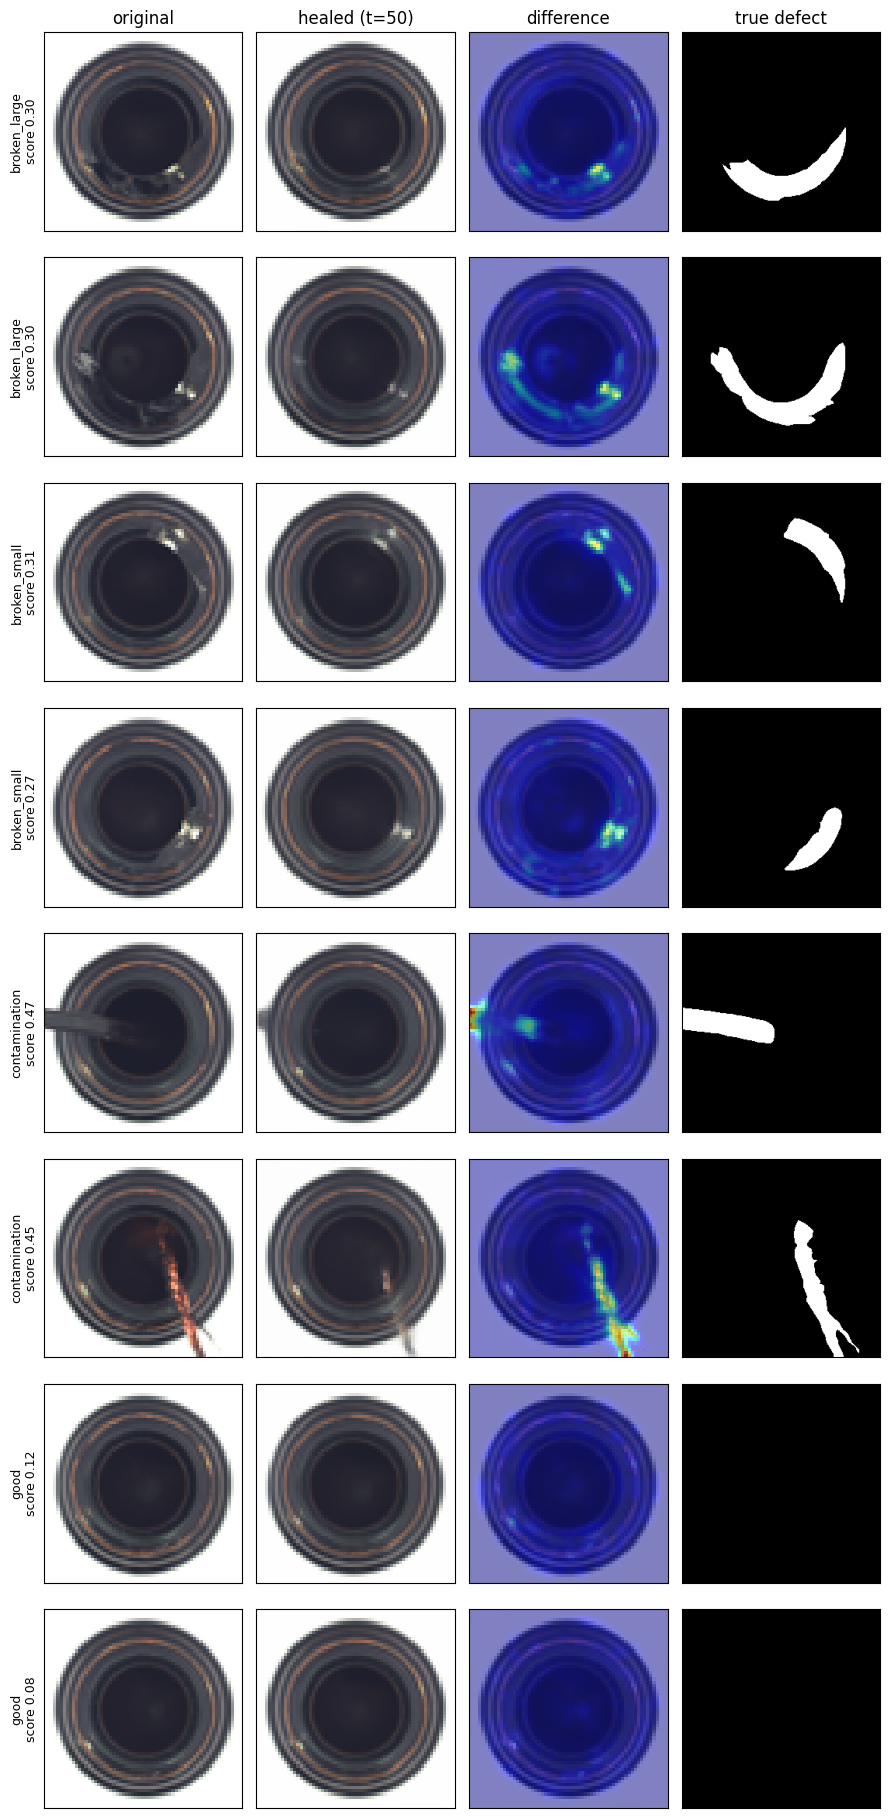

In [17]:
# Figure 1: original -> healed -> difference -> ground truth, two examples per type
pick = []
for d in np.unique(test_types):
    ids = np.where(test_types == d)[0]
    pick += list(ids[np.argsort(-img_scores[ids])][:2] if d != 'good' else ids[:2])
fig, ax = plt.subplots(len(pick), 4, figsize=(9, 2.3 * len(pick)))
for r, i in enumerate(pick):
    ax[r, 0].imshow(to_img(test_x[i]))
    ax[r, 1].imshow(to_img(best_healed[i]))
    ax[r, 2].imshow(to_img(test_x[i]), alpha=1.0)
    ax[r, 2].imshow(best_maps[i].numpy(),
                    cmap='jet', alpha=0.5, vmin=0, vmax=float(best_maps.max()))
    ax[r, 3].imshow(test_masks[i], cmap='gray')
    ax[r, 0].set_ylabel(f'{test_types[i]}\nscore {img_scores[i]:.2f}', fontsize=9)
for c, tname in enumerate(['original', f'healed (t={BEST_T})', 'difference', 'true defect']):
    ax[0, c].set_title(tname)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig_original_healed_difference.png'), dpi=150, bbox_inches='tight'); plt.show()

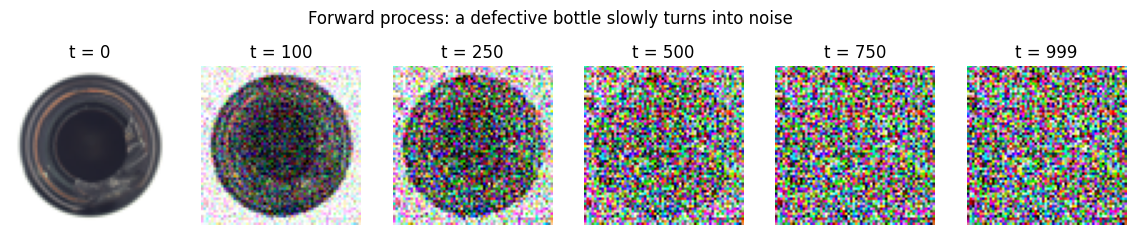

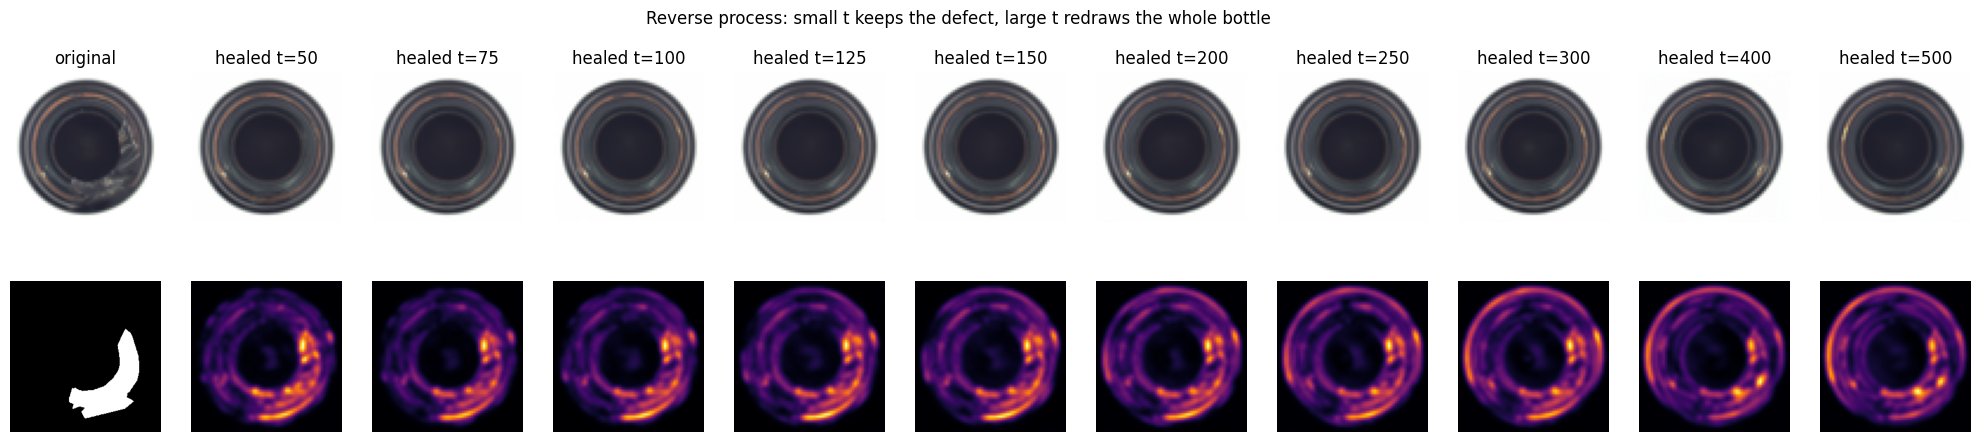

In [18]:
# Figure 2: the forward process (adding noise), for the 'diffusion forward and reverse' slide
i = int(np.where(test_types == 'broken_large')[0][0])
ts = [0, 100, 250, 500, 750, 999]
g = torch.Generator().manual_seed(SEED)
noise = torch.randn(test_x[i:i+1].shape, generator=g)
noisy = [test_x[i] if t == 0 else scheduler.add_noise(test_x[i:i+1], noise, torch.tensor([t]))[0] for t in ts]
fig, ax = plt.subplots(1, len(ts), figsize=(2.4 * len(ts), 2.8))
for a, im, t in zip(ax, noisy, ts):
    a.imshow(to_img(im)); a.set_title(f't = {t}'); a.axis('off')
plt.suptitle('Forward process: a defective bottle slowly turns into noise')
plt.savefig(os.path.join(OUT_DIR, 'fig_forward_process.png'), dpi=150, bbox_inches='tight'); plt.show()

# Figure 3: the same defect healed at different noise levels (reverse process)
levels = [t for t in NOISE_LEVELS if t in healed_by_t]
fig, ax = plt.subplots(2, len(levels) + 1, figsize=(2.3 * (len(levels) + 1), 5))
ax[0, 0].imshow(to_img(test_x[i])); ax[0, 0].set_title('original'); ax[1, 0].imshow(test_masks[i], cmap='gray')
for j, t in enumerate(levels, 1):
    ax[0, j].imshow(to_img(healed_by_t[t][i])); ax[0, j].set_title(f'healed t={t}')
    ax[1, j].imshow(anomaly_map(test_x[i:i+1], healed_by_t[t][i:i+1])[0], cmap='inferno')
for a in ax.ravel(): a.axis('off')
plt.suptitle('Reverse process: small t keeps the defect, large t redraws the whole bottle')
plt.savefig(os.path.join(OUT_DIR, 'fig_noise_levels.png'), dpi=150, bbox_inches='tight'); plt.show()

## 9 · Export for Sohail (results table) and Shruti (demo app)

In [25]:
# For Sohail: heatmaps + image scores, in the same order as the test files
np.savez_compressed(os.path.join(OUT_DIR, 'diffusion_heatmaps.npz'),
                    paths=np.array([os.path.relpath(p, BOTTLE) for p in test_paths]),
                    defect_type=test_types, label=test_labels,
                    heatmap_256=maps_eval.astype(np.float16), image_score=img_scores,
                    healed_64=((best_healed + 1) / 2).numpy().astype(np.float16), t_start=BEST_T)

# For Shruti: the trained model in a folder that loads with UNet2DModel.from_pretrained(...)
ema.save_pretrained(os.path.join(RUN_DIR, 'ddpm_bottle_ema'))
json.dump({'t_start': BEST_T, 'img_size': IMG_SIZE, 'blur_sigma': BLUR_SIGMA,
           'num_train_timesteps': NUM_TRAIN_TIMESTEPS},
          open(os.path.join(RUN_DIR, 'ddpm_bottle_ema', 'heal_config.json'), 'w'), indent=2)

def heal_single(pil_image, t_start=BEST_T):
    # For the demo: one PIL image -> (healed 64x64 image, heatmap 64x64, image score)
    arr = np.asarray(pil_image.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC), dtype=np.float32) / 255
    x = to_model([arr])
    h = heal(ema, x, t_start=t_start)
    m = anomaly_map(x, h)[0]
    return to_img(h[0]), m.numpy(), float(m.max())

hi, hm, sc = heal_single(Image.open(test_paths[-1]))
print('heal_single works. Score =', round(sc, 3))
print('\nFiles saved in', RUN_DIR)
for root, _, files in os.walk(RUN_DIR):
    for f in sorted(files):
        if not f.endswith('.pt'): print('  ', os.path.relpath(os.path.join(root, f), RUN_DIR))

heal_single works. Score = 0.103

Files saved in /content/drive/MyDrive/raju_diffusion
   results/diffusion_heatmaps.npz
   results/diffusion_per_type.csv
   results/diffusion_results.json
   results/fig_forward_process.png
   results/fig_noise_levels.png
   results/fig_original_healed_difference.png
   results/loss_curve.png
   results/noise_level_sweep.csv
   results/noise_level_sweep.png
   ddpm_bottle_ema/config.json
   ddpm_bottle_ema/diffusion_pytorch_model.safetensors
   ddpm_bottle_ema/heal_config.json


In [26]:
def detect(image):   # 256x256x3 uint8 -> 256x256 heatmap
    arr = np.asarray(Image.fromarray(image).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC), dtype=np.float32) / 255
    x = to_model([arr])
    m = anomaly_map(x, heal(ema, x, t_start=BEST_T))
    return F.interpolate(m[:, None], size=256, mode='bilinear', align_corners=False)[0, 0].numpy()

# quick test
test_img = np.asarray(Image.open(test_paths[0]).convert('RGB').resize((256, 256)))
hm = detect(test_img)
print(hm.shape, hm.max())   # should print (256, 256) and a number

(256, 256) 0.22286269


### If the results are weak
- **Large defects don't heal** (they still show in the healed image): increase *t*. The AnoDDPM paper uses **simplex noise** for this, which is a good next step to mention.
- **Good bottles light up everywhere:** *t* is too high, or the model needs more training. Train more steps by raising `TARGET_STEPS`; section 4 resumes where it stopped.
- **Generated bottles still look like noise:** train longer. A few thousand steps is not enough; you want 20k–40k.
- **Day 3, noon fallback:** keep the diffusion result and report it honestly. MLE and VAE still give a complete comparison.